# DAY1 실습 05 : Steel 전력 데이터

데이터 파일 : `Steel_industry_data.csv`
출처 : UCI Machine Learning Repository - [Steel Industry Energy Consumption](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption)

철강 공장의 2018년 1년치 전력 사용 기록이다. 15분마다 한 번씩 기록되어 총 35,040행이고, 한 줄이 15분 한 구간이다.
문제 아래 코드 셀에 직접 코드를 작성하고 실행해 본다.

| 컬럼 | 설명 |
|---|---|
| Usage_kWh | 15분 구간의 전력 사용량 (kWh) |
| Lagging_Current_Reactive.Power_kVarh | 지상 무효전력 (kVarh) |
| Leading_Current_Reactive_Power_kVarh | 진상 무효전력 (kVarh) |
| CO2(tCO2) | 탄소배출량 |
| Lagging_Current_Power_Factor | 지상 역률 (%) |
| Leading_Current_Power_Factor | 진상 역률 (%) |
| WeekStatus | 평일(Weekday) / 주말(Weekend) |
| Day_of_week | 요일 |
| Load_Type | 부하 유형 (Light_Load / Medium_Load / Maximum_Load) |

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "Steel_industry_data.csv")

df = pd.read_csv(csv_path)

data = df.copy()

### 1. `shape` / `columns` / `isna` : 행·열 수와 열 이름을 확인하고, `Usage_kWh`, `WeekStatus`, `Load_Type`의 결측값 수를 구하시오.

In [ ]:
print("행·열:", data.shape)
print("열 이름:", data.columns.tolist())
data[["Usage_kWh", "WeekStatus", "Load_Type"]].isna().sum()

행·열: (35040, 11)
열 이름: ['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


Usage_kWh     0
WeekStatus    0
Load_Type     0
dtype: int64

### 2. `value_counts` / `mode` : `Load_Type`의 빈도와 백분율(%)을 한 표로 만들고, 최빈값을 구하시오.

In [ ]:
display(pd.DataFrame({
    "빈도": data["Load_Type"].value_counts(),
    "백분율(%)": (data["Load_Type"].value_counts(normalize=True) * 100).round(2)
}))
print("최빈값:", data["Load_Type"].mode()[0])

,빈도,백분율(%)
Load_Type,,
Light_Load,18072,51.58
Medium_Load,9696,27.67
Maximum_Load,7272,20.75


최빈값: Light_Load


### 3. 막대그래프 : `Load_Type`별 빈도를 막대그래프로 그리시오. 제목과 축 이름을 넣으시오.

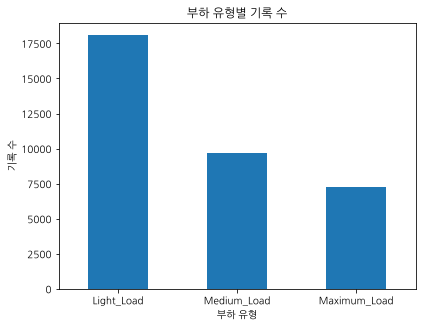

In [ ]:
data["Load_Type"].value_counts().plot.bar()
plt.title("부하 유형별 기록 수")
plt.xlabel("부하 유형")
plt.ylabel("기록 수")
plt.xticks(rotation=0)
plt.show()

### 4. `mean` / `median` : `Usage_kWh`의 평균과 중앙값을 구하시오.

In [ ]:
usage = data["Usage_kWh"]
print("평균:", round(usage.mean(), 2))
print("중앙값:", round(usage.median(), 2))

평균: 27.39
중앙값: 4.57


### 5. 산포 : `Usage_kWh`의 범위, Q1, Q3, IQR, 표준편차(ddof=1), 변동계수(CV, %)를 구하시오.

In [ ]:
q1 = usage.quantile(0.25)
q3 = usage.quantile(0.75)
iqr = q3 - q1
print("범위:", round(usage.max() - usage.min(), 2))
print("Q1, Q3, IQR:", round(q1, 2), round(q3, 2), round(iqr, 2))
print("표준편차:", round(usage.std(ddof=1), 2))
print("CV(%):", round(usage.std(ddof=1) / usage.mean() * 100, 2))

범위: 157.18
Q1, Q3, IQR: 3.2 51.24 48.04
표준편차: 33.44
CV(%): 122.12


### 6. `describe` : 숫자 열 여섯 개를 `describe()`로 한 번에 요약하시오.

In [ ]:
num_cols = ["Usage_kWh", "Lagging_Current_Reactive.Power_kVarh", "Leading_Current_Reactive_Power_kVarh",
            "CO2(tCO2)", "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor"]
data[num_cols].describe().round(2)

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor
count,35040.00,35040.00,35040.00,35040.00,35040.00,35040.00
mean,27.39,13.04,3.87,0.01,80.58,84.37
std,33.44,16.31,7.42,0.02,18.92,30.46
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,3.20,2.30,0.00,0.00,63.32,99.70
50%,4.57,5.00,0.00,0.00,87.96,100.00
75%,51.24,22.64,2.09,0.02,99.02,100.00
max,157.18,96.91,27.76,0.07,100.00,100.00


### 7. 히스토그램 : `Usage_kWh`의 히스토그램을 `bins=30`으로 그리고, 평균(빨간 점선)과 중앙값(검은 점선)을 표시하시오.

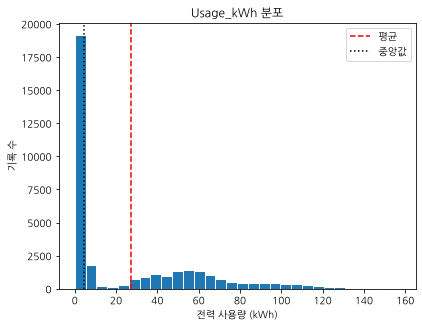

In [ ]:
plt.hist(usage, bins=30, edgecolor="white")
plt.axvline(usage.mean(), color="red", linestyle="--", label="평균")
plt.axvline(usage.median(), color="black", linestyle=":", label="중앙값")
plt.title("Usage_kWh 분포")
plt.xlabel("전력 사용량 (kWh)")
plt.ylabel("기록 수")
plt.legend()
plt.show()

### 8. 박스플롯 : `Usage_kWh`의 박스플롯을 평균과 함께 그리시오.

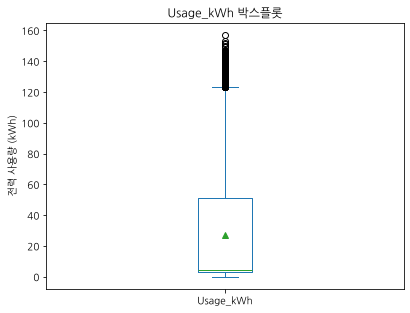

In [ ]:
usage.plot.box(showmeans=True)
plt.title("Usage_kWh 박스플롯")
plt.ylabel("전력 사용량 (kWh)")
plt.show()

### 9. IQR 기준 이상값 후보 : `Usage_kWh`의 하한(Q1 − 1.5 × IQR), 상한(Q3 + 1.5 × IQR)과 경계 밖 기록 수를 구하시오.

In [ ]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
is_outlier = (usage < lower) | (usage > upper)
print("하한, 상한:", round(lower, 2), round(upper, 2))
print("IQR 기준 이상값 후보:", is_outlier.sum())

하한, 상한: -68.86 123.29
IQR 기준 이상값 후보: 328


### 10. z점수 : `Usage_kWh`의 z점수를 구하고 `|z| > 3`인 기록 수를 구하시오. 9번의 IQR 기준 후보 수와 비교하시오.

In [ ]:
z = (usage - usage.mean()) / usage.std(ddof=1)
print("z점수 기준 이상값 후보:", (z.abs() > 3).sum())
print("IQR 기준 이상값 후보:", is_outlier.sum())

z점수 기준 이상값 후보: 212
IQR 기준 이상값 후보: 328


### 11. `skew` / `kurt` : `Usage_kWh`의 왜도와 초과첨도를 구하시오.

In [ ]:
print("왜도:", round(usage.skew(), 3))
print("초과첨도:", round(usage.kurt(), 3))

왜도: 1.197
초과첨도: 0.391


### 12. 이상값 후보의 부하 유형 : 9번의 이상값 후보만 골라 `Load_Type`별 기록 수를 구하시오.

In [ ]:
data.loc[is_outlier, "Load_Type"].value_counts()

Load_Type
Maximum_Load    149
Medium_Load     146
Light_Load       33
Name: count, dtype: int64

## 확인문제

앞의 결과를 보고 답을 1~2문장으로 적으시오.

### 확인 1. `Usage_kWh`의 평균(27.39 kWh)과 중앙값(4.57 kWh) 중 '보통의 15분 기록'을 더 잘 나타내는 값은 무엇인가? 이유는?

**답 :** 중앙값이다. 기록의 절반이 4.57 kWh 이하인데, 사용량이 큰 일부 기록이 평균을 27.39 kWh 까지 끌어올렸기 때문이다.

### 확인 2. 7번 히스토그램에서 봉우리는 몇 개이고, 평균선은 어디에 그어졌는가? 이 결과로 볼 때 평균 하나로 전체를 요약해도 되는가?

**답 :** 봉우리는 0 ~ 5 kWh 근처와 50 ~ 60 kWh 근처에 두 개다. 평균선은 두 봉우리 사이 기록이 적은 곳에 있어서, 평균 하나로는 어느 쪽 기록도 대표하지 못한다.

### 확인 3. `Usage_kWh`의 CV가 122%로 나왔다. 이 값은 무엇을 뜻하는가?

**답 :** 표준편차(33.44 kWh)가 평균(27.39 kWh)보다 크다는 뜻이다. 평균에 비해 값이 매우 넓게 흩어져 있다.

### 확인 4. 9번에서 IQR 기준 하한이 음수(−68.86 kWh)로 나왔다. 박스플롯에서 이상값 후보가 위쪽에만 보이는 이유는?

**답 :** 전력 사용량은 0보다 작은 값이 없어서 음수인 하한보다 작은 기록이 생길 수 없다. 그래서 후보 328건은 모두 상한(123.29 kWh)보다 큰 쪽이다.

### 확인 5. IQR 기준 후보(328건)와 z점수 기준 후보(212건)의 수가 다른 이유는?

**답 :** IQR 기준은 사분위수를, z점수 기준은 평균과 표준편차를 쓰기 때문이다. 큰 값 쪽으로 치우친 자료라 표준편차가 커져서 z점수 경계(약 127.7 kWh)가 IQR 상한(123.29 kWh)보다 높아졌다.

### 확인 6. `Usage_kWh`의 왜도는 1.197이다. 왜도의 부호와 평균·중앙값의 관계가 서로 맞는가?

**답 :** 맞다. 왜도가 양수이면 오른쪽(큰 값 쪽) 꼬리가 길고 평균이 중앙값보다 크다. 실제로 평균 27.39 kWh가 중앙값 4.57 kWh보다 크다.

## 개념 확인

알맞은 답을 하나 고르시오.

### 개념 1. 다음 중 순서형 변수는?

① 작업조 (주간·야간)

② 품질 등급 (1등급·2등급·3등급)

③ 불량 개수

④ 설비 코드 (MC01·MC02)

**답 :** ②

등급 사이에 순서는 있지만 단계 사이의 간격이 같다고 보장할 수 없다. ①·④는 명목형, ③은 이산형(수치형)이다.

### 개념 2. 설비 정지 시간(분) [4, 5, 5, 6, 60]의 중심을 나타내기에 가장 알맞은 것은?

① 평균 16분 : 모든 값을 반영한다

② 중앙값 5분 : 극단값 60의 영향을 덜 받는다

③ 최빈값 5분 : 가장 큰 값을 반영한다

④ 범위 56분 : 전체 폭을 나타낸다

**답 :** ②

60분 하나가 평균을 16분으로 끌어올려 평균이 대부분의 값과 멀어졌다. ④ 범위는 대표값이 아니라 산포 지표다.

### 개념 3. 공구마모 시간(min) 자료에서 원자료와 단위가 다른 통계량은?

① 표준편차

② IQR

③ 분산

④ 범위

**답 :** ③

분산은 편차를 제곱해서 구하므로 단위가 (min)²이다. 나머지는 모두 min이다.

### 개념 4. 공정 A는 평균 200g·표준편차 10g, 공정 B는 평균 50g·표준편차 4g이다. 옳은 설명은?

① 표준편차가 큰 A가 평균 대비 퍼짐도 크다

② B의 CV가 8%로 A(5%)보다 평균 대비 퍼짐이 크다

③ 두 공정의 CV는 같다

④ 평균이 다르면 퍼짐을 비교할 수 없다

**답 :** ②

CV = 표준편차 ÷ 평균 × 100이다. A는 10 ÷ 200 × 100 = 5%, B는 4 ÷ 50 × 100 = 8%다. 평균 규모가 다른 자료의 퍼짐은 CV로 비교한다.

### 개념 5. Q1 = 20, Q3 = 30인 자료에서 IQR 기준(1.5 × IQR)으로 이상값 후보인 값은?

① 8

② 25

③ 44

④ 50

**답 :** ④

IQR = 10, 1.5 × IQR = 15다. 하한은 20 − 15 = 5, 상한은 30 + 15 = 45다. 이 범위를 벗어난 값은 50뿐이다.